<a href="https://colab.research.google.com/github/durgeshM-ai/Data-Science-Projects/blob/master/stochastic_stock_simulation_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q yfinance

# Stochastic Processes Problem Set – Modeling Stock Price Movements
**Google Colab Notebook (`yfinance` Tier-1 Data Pipeline)**

This notebook programmatically fetches daily closing prices from **Yahoo Finance (`yfinance`)** for `AAPL`, `MSFT`, and `NVDA`, preprocesses the time series, calibrates **Geometric Brownian Motion (GBM)**, **Exponential Ornstein-Uhlenbeck (OU)**, and **Merton Jump-Diffusion (MJD)** models, runs 1,000 Monte Carlo simulations across 30-, 60-, and 180-trading-day horizons, and renders all 6 publication-grade figures inline.

In [ ]:
"""
================================================================================
STOCHASTIC PROCESSES PROBLEM SET: MODELING STOCK PRICE MOVEMENTS
Quantitative Financial Research & Monte Carlo Simulation Engine (Google Colab)
================================================================================

README:
---------------------------------------------
Overview:
   This script implements an end-to-end quantitative modeling pipeline that:
   - Programmatically fetches historical daily closing prices from Yahoo Finance
     (`yfinance`) for three large-cap U.S. technology equities:
     Apple Inc. (AAPL), Microsoft Corp. (MSFT), and NVIDIA Corp. (NVDA).
   - Cleans and preprocesses the time series (business-day alignment, forward-fill
     imputation, log-return calculation, Jarque-Bera normality tests, and
     Dickey-Fuller stationarity diagnostics).
   - Calibrates three stochastic differential equation (SDE) models via Maximum
     Likelihood Estimation (MLE), OLS regression, and iterative jump-threshold
     filtering:
       (a) Geometric Brownian Motion (GBM)
       (b) Exponential Ornstein-Uhlenbeck (Mean-Reverting) Process (OU)
       (c) Merton Jump-Diffusion (MJD) Model
   - Runs vectorized Monte Carlo simulations (M = 1,000 paths, seed = 42) over
     short-, medium-, and long-term horizons (30, 60, and 180 trading days).
   - Computes comprehensive risk and performance metrics (Expected Return,
     Probability of Loss, 95% Value-at-Risk [VaR], 95% Conditional VaR [CVaR],
     Mean Maximum Drawdown, and Return-to-VaR Ratio) and generates 6 publication-
     quality visual figures displayed inline in Google Colab and saved to disk.
"""

from __future__ import annotations

import argparse
import json
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from scipy import stats

In [ ]:
# ==============================================================================
# 1. GLOBAL CONFIGURATION & STYLING
# ==============================================================================

TRADING_DAYS_PER_YEAR: int = 252
DEFAULT_SUBSET_HORIZONS: Tuple[int, ...] = (30, 60, 180)
DEFAULT_MONTE_CARLO_RUNS: int = 1000
GLOBAL_SEED: int = 42

DEFAULT_TICKERS: List[str] = ["AAPL", "MSFT", "NVDA"]
DEFAULT_START_DATE: str = "2025-10-24"
DEFAULT_END_DATE: str = "2026-10-24"

PALETTE: Dict[str, str] = {
    "GBM": "#1f4e78",        # Deep Navy Blue
    "OU": "#2e8b57",         # Sea Green
    "MJD": "#b22222",        # Crimson Red
    "HIST": "#111827",       # Charcoal Black
    "CI_GBM": "#6baed6",     # Soft Blue
    "CI_OU": "#74c476",      # Soft Green
    "CI_MJD": "#fb6a4a",     # Soft Coral
    "GRID": "#e5e7eb",       # Light Gray
}

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": PALETTE["GRID"],
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 180,
})


# ==============================================================================
# 2. DATA STRUCTURES FOR CALIBRATED PARAMETERS & SIMULATION METRICS
# ==============================================================================

@dataclass
class HistoricalSummary:
    ticker: str
    start_date: str
    end_date: str
    n_obs: int
    start_price: float
    end_price: float
    min_price: float
    max_price: float
    total_return_pct: float
    daily_mean_log_ret: float
    daily_std_log_ret: float
    annualized_drift_pct: float
    annualized_vol_pct: float
    skewness: float
    excess_kurtosis: float
    jarque_bera_stat: float
    jarque_bera_pval: float
    autocorr_lag1: float
    dickey_fuller_tstat: float
    historical_max_drawdown_pct: float
    jump_days_count_22sigma: int
    jump_days_count_25sigma: int
    jump_days_count_30sigma: int


@dataclass
class GBMParams:
    mu_annual: float
    sigma_annual: float
    log_likelihood: float
    aic: float
    bic: float


@dataclass
class OUParams:
    kappa_annual: float
    theta_log: float
    theta_price: float
    sigma_ou_annual: float
    half_life_days: float
    ar1_slope: float
    ar1_intercept: float
    log_likelihood: float
    aic: float
    bic: float


@dataclass
class MJDParams:
    mu_annual: float
    sigma_diff_annual: float
    lambda_annual: float
    mu_j: float
    delta_j: float
    k_expected_jump: float
    threshold_z: float
    detected_jumps: int
    log_likelihood: float
    aic: float
    bic: float


@dataclass
class HorizonMetrics:
    ticker: str
    model: str
    horizon_days: int
    initial_price: float
    mean_terminal_price: float
    median_terminal_price: float
    std_terminal_price: float
    ci_5_price: float
    ci_25_price: float
    ci_75_price: float
    ci_95_price: float
    expected_return_pct: float
    median_return_pct: float
    prob_loss_pct: float
    prob_gain_10pct: float
    var_95_loss_pct: float
    cvar_95_loss_pct: float
    var_95_dollar: float
    cvar_95_dollar: float
    mean_max_drawdown_pct: float
    sharpe_like_ratio: float


# ==============================================================================
# 3. DATA COLLECTION & PREPROCESSING PIPELINE (YFINANCE)
# ==============================================================================

def fetch_yfinance_data(
    tickers: List[str],
    start_date: str = DEFAULT_START_DATE,
    end_date: str = DEFAULT_END_DATE,
    csv_cache_path: Path | None = None,
) -> pd.DataFrame:
    """
    Programmatically downloads historical daily closing prices from Yahoo Finance
    using `yfinance.download()`.
    """
    print(f"[INFO] Downloading historical daily closing prices via yfinance for {tickers}...")
    raw = yf.download(
        tickers=tickers,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False,
    )
    if raw is None or raw.empty:
        raise RuntimeError(
            "No data returned from yfinance. Please check your internet connection or date window."
        )

    if isinstance(raw.columns, pd.MultiIndex):
        df = raw["Close"].copy()
    elif "Close" in raw.columns:
        df = raw[["Close"]].copy()
        df.columns = tickers
    else:
        df = raw.copy()

    df.index = pd.to_datetime(df.index).tz_localize(None)
    df.index.name = "Date"
    df = df[[t for t in tickers if t in df.columns]].sort_index()

    if csv_cache_path is not None:
        csv_cache_path.parent.mkdir(parents=True, exist_ok=True)
        df.to_csv(csv_cache_path)

    print(f"[INFO] Successfully downloaded {len(df)} trading days from Yahoo Finance.")
    return df


def clean_and_preprocess_data(
    raw_df: pd.DataFrame,
) -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, HistoricalSummary]]:
    """
    Cleans and preprocesses historical stock price data:
      1. Sorts chronological index and removes duplicate timestamps.
      2. Forward-fills isolated missing values up to 3 consecutive business days
         and drops any unaligned rows.
      3. Validates strictly positive prices and computes continuously compounded
         daily log-returns: r_t = ln(S_t / S_{t-1}).
      4. Computes descriptive statistics, Jarque-Bera normality tests,
         Dickey-Fuller stationarity t-statistics, and empirical jump counts.
    """
    df = raw_df.copy().sort_index()
    df = df[~df.index.duplicated(keep="first")]
    df = df.ffill(limit=3).dropna(how="any")

    if (df <= 0).any().any():
        raise ValueError("Stock prices must be strictly positive for log-return modeling.")

    log_returns = np.log(df / df.shift(1)).dropna(how="any")
    summaries: Dict[str, HistoricalSummary] = {}

    for ticker in df.columns:
        prices = df[ticker].values
        rets = log_returns[ticker].values
        n_obs = len(prices)

        start_p = float(prices[0])
        end_p = float(prices[-1])
        min_p = float(np.min(prices))
        max_p = float(np.max(prices))
        total_ret_pct = (end_p / start_p - 1.0) * 100.0

        mean_r = float(np.mean(rets))
        std_r = float(np.std(rets, ddof=1))
        ann_vol = std_r * np.sqrt(TRADING_DAYS_PER_YEAR)
        ann_drift = (mean_r + 0.5 * std_r**2) * TRADING_DAYS_PER_YEAR

        skew = float(stats.skew(rets, bias=False))
        kurt = float(stats.kurtosis(rets, fisher=True, bias=False))
        jb_stat, jb_pval = stats.jarque_bera(rets)

        autocorr_1 = float(np.corrcoef(rets[:-1], rets[1:])[0, 1])

        # Dickey-Fuller regression on log-prices: delta_X_t = a + phi * X_{t-1} + eps_t
        log_p = np.log(prices)
        delta_x = np.diff(log_p)
        x_lag = log_p[:-1]
        slope, intercept, _, _, std_err = stats.linregress(x_lag, delta_x)
        df_tstat = float(slope / std_err)

        # Historical maximum drawdown
        running_max = np.maximum.accumulate(prices)
        drawdowns = (prices - running_max) / running_max
        max_dd_pct = float(np.min(drawdowns) * 100.0)

        # Standardized return outliers (jump detection across multiple thresholds)
        z_scores = np.abs((rets - mean_r) / std_r)
        jumps_22 = int(np.sum(z_scores > 2.2))
        jumps_25 = int(np.sum(z_scores > 2.5))
        jumps_30 = int(np.sum(z_scores > 3.0))

        summaries[ticker] = HistoricalSummary(
            ticker=ticker,
            start_date=str(df.index[0].date()),
            end_date=str(df.index[-1].date()),
            n_obs=n_obs,
            start_price=round(start_p, 2),
            end_price=round(end_p, 2),
            min_price=round(min_p, 2),
            max_price=round(max_p, 2),
            total_return_pct=round(total_ret_pct, 2),
            daily_mean_log_ret=round(mean_r, 6),
            daily_std_log_ret=round(std_r, 6),
            annualized_drift_pct=round(ann_drift * 100.0, 2),
            annualized_vol_pct=round(ann_vol * 100.0, 2),
            skewness=round(skew, 4),
            excess_kurtosis=round(kurt, 4),
            jarque_bera_stat=round(float(jb_stat), 2),
            jarque_bera_pval=float(jb_pval),
            autocorr_lag1=round(autocorr_1, 4),
            dickey_fuller_tstat=round(df_tstat, 4),
            historical_max_drawdown_pct=round(max_dd_pct, 2),
            jump_days_count_22sigma=jumps_22,
            jump_days_count_25sigma=jumps_25,
            jump_days_count_30sigma=jumps_30,
        )

    return df, log_returns, summaries


In [ ]:
# ==============================================================================
# 4. PARAMETER CALIBRATION FOR STOCHASTIC PROCESS MODELS
# ==============================================================================

def calibrate_gbm(log_returns: np.ndarray, dt: float = 1.0 / TRADING_DAYS_PER_YEAR) -> GBMParams:
    """
    Calibrates Geometric Brownian Motion (GBM):
        dS_t = mu * S_t * dt + sigma * S_t * dW_t
    """
    n = len(log_returns)
    mean_r = float(np.mean(log_returns))
    std_r = float(np.std(log_returns, ddof=1))

    sigma_annual = std_r / np.sqrt(dt)
    mu_annual = (mean_r / dt) + 0.5 * (sigma_annual ** 2)

    ll = float(np.sum(stats.norm.logpdf(log_returns, loc=mean_r, scale=std_r)))
    k_params = 2
    aic = 2 * k_params - 2 * ll
    bic = k_params * np.log(n) - 2 * ll

    return GBMParams(
        mu_annual=round(mu_annual, 6),
        sigma_annual=round(sigma_annual, 6),
        log_likelihood=round(ll, 2),
        aic=round(aic, 2),
        bic=round(bic, 2),
    )


def calibrate_ou(prices: np.ndarray, dt: float = 1.0 / TRADING_DAYS_PER_YEAR) -> OUParams:
    """
    Calibrates the Exponential Ornstein-Uhlenbeck (Mean-Reverting) Process on log-prices X_t = ln(S_t):
        dX_t = kappa * (theta - X_t) * dt + sigma_ou * dW_t
    """
    x = np.log(prices)
    x_t = x[:-1]
    x_next = x[1:]
    n = len(x_t)

    slope, intercept, _, _, _ = stats.linregress(x_t, x_next)
    b = float(np.clip(slope, 0.85, 0.9985))
    a = float(intercept)

    kappa_annual = -np.log(b) / dt
    theta_log = float(a / (1.0 - slope)) if (1.0 - slope) > 0.005 else float(np.mean(x))
    theta_log = float(np.clip(theta_log, np.min(x) - 0.5, np.max(x) + 0.5))
    theta_price = float(np.exp(theta_log))

    residuals = x_next - (a + slope * x_t)
    s_eps = float(np.std(residuals, ddof=2))
    sigma_ou_annual = s_eps * np.sqrt((-2.0 * np.log(b)) / (dt * (1.0 - b**2)))

    half_life_years = np.log(2.0) / kappa_annual
    half_life_days = half_life_years * TRADING_DAYS_PER_YEAR

    ll = float(np.sum(stats.norm.logpdf(residuals, loc=0.0, scale=s_eps)))
    k_params = 3
    aic = 2 * k_params - 2 * ll
    bic = k_params * np.log(n) - 2 * ll

    return OUParams(
        kappa_annual=round(float(kappa_annual), 6),
        theta_log=round(float(theta_log), 6),
        theta_price=round(float(theta_price), 2),
        sigma_ou_annual=round(float(sigma_ou_annual), 6),
        half_life_days=round(float(half_life_days), 2),
        ar1_slope=round(float(b), 6),
        ar1_intercept=round(float(a), 6),
        log_likelihood=round(ll, 2),
        aic=round(aic, 2),
        bic=round(bic, 2),
    )


def calibrate_mjd(
    log_returns: np.ndarray,
    dt: float = 1.0 / TRADING_DAYS_PER_YEAR,
    threshold_z: float = 2.2,
) -> MJDParams:
    """
    Calibrates Merton's (1976) Jump-Diffusion Model:
        dS_t / S_{t-} = (mu - lambda * k) dt + sigma_diff dW_t + (Y - 1) dN_t
    """
    n = len(log_returns)
    r = log_returns.copy()

    mask_diff = np.ones(n, dtype=bool)
    for _ in range(5):
        diff_rets = r[mask_diff]
        m_diff = np.mean(diff_rets)
        s_diff = np.std(diff_rets, ddof=1)
        new_mask = np.abs(r - m_diff) <= threshold_z * s_diff
        if np.array_equal(new_mask, mask_diff):
            break
        mask_diff = new_mask

    jump_mask = ~mask_diff
    n_jumps = int(np.sum(jump_mask))
    diff_rets = r[mask_diff]
    jump_rets = r[jump_mask]

    m_diff = float(np.mean(diff_rets))
    s_diff = float(np.std(diff_rets, ddof=1))
    sigma_diff_annual = s_diff / np.sqrt(dt)

    if n_jumps >= 2:
        lambda_annual = n_jumps / (n * dt)
        mu_j = float(np.mean(jump_rets) - m_diff)
        var_jump_obs = float(np.var(jump_rets, ddof=1))
        delta_j = float(np.sqrt(max(var_jump_obs - s_diff**2, (1.5 * s_diff)**2)))
    else:
        lambda_annual = 2.0 / (n * dt)
        mu_j = float(np.mean(r[np.abs(r - m_diff) > 1.8 * s_diff]) - m_diff)
        delta_j = float(2.0 * s_diff)

    k_expected = float(np.exp(mu_j + 0.5 * delta_j**2) - 1.0)
    total_mean_r = float(np.mean(r))
    mu_annual = (total_mean_r / dt) + 0.5 * sigma_diff_annual**2

    lam_dt = lambda_annual * dt
    drift_diff_dt = (mu_annual - 0.5 * sigma_diff_annual**2 - lambda_annual * k_expected) * dt
    var_diff_dt = (sigma_diff_annual**2) * dt

    pdf_total = np.zeros_like(r, dtype=float)
    for k_jump in range(5):
        p_k = stats.poisson.pmf(k_jump, lam_dt)
        mean_k = drift_diff_dt + k_jump * mu_j
        std_k = np.sqrt(var_diff_dt + k_jump * (delta_j**2))
        pdf_total += p_k * stats.norm.pdf(r, loc=mean_k, scale=std_k)

    ll = float(np.sum(np.log(np.maximum(pdf_total, 1e-300))))
    k_params = 5
    aic = 2 * k_params - 2 * ll
    bic = k_params * np.log(n) - 2 * ll

    return MJDParams(
        mu_annual=round(mu_annual, 6),
        sigma_diff_annual=round(sigma_diff_annual, 6),
        lambda_annual=round(lambda_annual, 4),
        mu_j=round(mu_j, 6),
        delta_j=round(delta_j, 6),
        k_expected_jump=round(k_expected, 6),
        threshold_z=threshold_z,
        detected_jumps=n_jumps,
        log_likelihood=round(ll, 2),
        aic=round(aic, 2),
        bic=round(bic, 2),
    )


In [ ]:

# ==============================================================================
# 5. VECTORIZED MONTE CARLO SIMULATION ENGINES
# ==============================================================================

def simulate_gbm_paths(
    s0: float,
    params: GBMParams,
    horizon_days: int,
    n_sims: int,
    rng: np.random.Generator,
    dt: float = 1.0 / TRADING_DAYS_PER_YEAR,
) -> np.ndarray:
    z = rng.standard_normal(size=(n_sims, horizon_days))
    drift_step = (params.mu_annual - 0.5 * (params.sigma_annual ** 2)) * dt
    vol_step = params.sigma_annual * np.sqrt(dt)
    log_increments = drift_step + vol_step * z

    log_paths = np.zeros((n_sims, horizon_days + 1), dtype=float)
    log_paths[:, 0] = np.log(s0)
    log_paths[:, 1:] = np.log(s0) + np.cumsum(log_increments, axis=1)
    return np.exp(log_paths)


def simulate_ou_paths(
    s0: float,
    params: OUParams,
    horizon_days: int,
    n_sims: int,
    rng: np.random.Generator,
    dt: float = 1.0 / TRADING_DAYS_PER_YEAR,
) -> np.ndarray:
    z = rng.standard_normal(size=(n_sims, horizon_days))
    exp_k = np.exp(-params.kappa_annual * dt)
    cond_std = params.sigma_ou_annual * np.sqrt(
        (1.0 - np.exp(-2.0 * params.kappa_annual * dt)) / (2.0 * params.kappa_annual)
    )

    x_paths = np.zeros((n_sims, horizon_days + 1), dtype=float)
    x_paths[:, 0] = np.log(s0)
    for t in range(horizon_days):
        x_paths[:, t + 1] = (
            x_paths[:, t] * exp_k
            + params.theta_log * (1.0 - exp_k)
            + cond_std * z[:, t]
        )
    return np.exp(x_paths)


def simulate_mjd_paths(
    s0: float,
    params: MJDParams,
    horizon_days: int,
    n_sims: int,
    rng: np.random.Generator,
    dt: float = 1.0 / TRADING_DAYS_PER_YEAR,
) -> np.ndarray:
    z_diff = rng.standard_normal(size=(n_sims, horizon_days))
    z_jump = rng.standard_normal(size=(n_sims, horizon_days))
    n_jumps = rng.poisson(lam=params.lambda_annual * dt, size=(n_sims, horizon_days))

    drift_step = (
        params.mu_annual
        - 0.5 * (params.sigma_diff_annual ** 2)
        - params.lambda_annual * params.k_expected_jump
    ) * dt
    diff_step = params.sigma_diff_annual * np.sqrt(dt) * z_diff
    jump_step = n_jumps * params.mu_j + np.sqrt(n_jumps) * params.delta_j * z_jump

    log_increments = drift_step + diff_step + jump_step
    log_paths = np.zeros((n_sims, horizon_days + 1), dtype=float)
    log_paths[:, 0] = np.log(s0)
    log_paths[:, 1:] = np.log(s0) + np.cumsum(log_increments, axis=1)
    return np.exp(log_paths)


In [ ]:
# ==============================================================================
# 6. STATISTICAL EVALUATION & RISK METRICS
# ==============================================================================

def evaluate_simulation_paths(
    ticker: str,
    model_name: str,
    paths: np.ndarray,
    horizon_days: int,
) -> HorizonMetrics:
    sub_paths = paths[:, : horizon_days + 1]
    s0 = float(sub_paths[0, 0])
    s_T = sub_paths[:, -1]

    simple_returns_pct = (s_T / s0 - 1.0) * 100.0
    dollar_pnl = s_T - s0

    mean_p = float(np.mean(s_T))
    med_p = float(np.median(s_T))
    std_p = float(np.std(s_T, ddof=1))
    ci_5, ci_25, ci_75, ci_95 = [
        float(x) for x in np.percentile(s_T, [5.0, 25.0, 75.0, 95.0])
    ]

    exp_ret_pct = float(np.mean(simple_returns_pct))
    med_ret_pct = float(np.median(simple_returns_pct))
    prob_loss_pct = float(np.mean(s_T < s0) * 100.0)
    prob_gain_10pct = float(np.mean(s_T >= 1.10 * s0) * 100.0)

    q5_ret = float(np.percentile(simple_returns_pct, 5.0))
    var_95_loss_pct = -q5_ret
    tail_losses_pct = simple_returns_pct[simple_returns_pct <= q5_ret]
    cvar_95_loss_pct = -float(np.mean(tail_losses_pct))

    q5_dollar = float(np.percentile(dollar_pnl, 5.0))
    var_95_dollar = -q5_dollar
    cvar_95_dollar = -float(np.mean(dollar_pnl[dollar_pnl <= q5_dollar]))

    running_peaks = np.maximum.accumulate(sub_paths, axis=1)
    drawdowns = (sub_paths - running_peaks) / running_peaks
    max_dd_per_path = np.min(drawdowns, axis=1) * 100.0
    mean_max_dd_pct = float(np.mean(max_dd_per_path))

    ret_std = float(np.std(simple_returns_pct, ddof=1))
    sharpe_like = exp_ret_pct / ret_std if ret_std > 0 else 0.0

    return HorizonMetrics(
        ticker=ticker,
        model=model_name,
        horizon_days=horizon_days,
        initial_price=round(s0, 2),
        mean_terminal_price=round(mean_p, 2),
        median_terminal_price=round(med_p, 2),
        std_terminal_price=round(std_p, 2),
        ci_5_price=round(ci_5, 2),
        ci_25_price=round(ci_25, 2),
        ci_75_price=round(ci_75, 2),
        ci_95_price=round(ci_95, 2),
        expected_return_pct=round(exp_ret_pct, 2),
        median_return_pct=round(med_ret_pct, 2),
        prob_loss_pct=round(prob_loss_pct, 2),
        prob_gain_10pct=round(prob_gain_10pct, 2),
        var_95_loss_pct=round(var_95_loss_pct, 2),
        cvar_95_loss_pct=round(cvar_95_loss_pct, 2),
        var_95_dollar=round(var_95_dollar, 2),
        cvar_95_dollar=round(cvar_95_dollar, 2),
        mean_max_drawdown_pct=round(mean_max_dd_pct, 2),
        sharpe_like_ratio=round(sharpe_like, 3),
    )



In [ ]:
# ==============================================================================
# 7. VISUALIZATION SUITE (DISPLAYS INLINE IN COLAB & SAVES HIGH-DPI PNGS)
# ==============================================================================

def plot_historical_overview(
    prices_df: pd.DataFrame,
    log_returns_df: pd.DataFrame,
    summaries: Dict[str, HistoricalSummary],
    out_path: Path,
    show_inline: bool = True,
) -> None:
    fig = plt.figure(figsize=(14, 8.5))
    gs = gridspec.GridSpec(2, 3, height_ratios=[1.15, 1.0], hspace=0.38, wspace=0.26)

    ax_top = fig.add_subplot(gs[0, :])
    norm_prices = prices_df / prices_df.iloc[0] * 100.0
    colors = {"AAPL": "#1f4e78", "MSFT": "#2e8b57", "NVDA": "#b22222"}

    for ticker in prices_df.columns:
        s = summaries[ticker]
        label = (
            f"{ticker}: ${s.start_price:.2f} -> ${s.end_price:.2f} "
            f"({s.total_return_pct:+.1f}%, Ann. Vol: {s.annualized_vol_pct:.1f}%)"
        )
        ax_top.plot(norm_prices.index, norm_prices[ticker], lw=2.2, color=colors.get(ticker, "#1f4e78"), label=label)

    ax_top.axhline(100.0, color="#64748b", ls=":", lw=1.1)
    ax_top.set_title(
        f"A. Historical Daily Closing Prices Indexed to Base 100 (N = {len(prices_df)} Trading Days)",
        fontsize=12,
        fontweight="bold",
        pad=10,
        loc="left",
    )
    ax_top.set_ylabel("Normalized Price Index (Base = 100)", fontsize=10)
    ax_top.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.92, fontsize=9.5)

    for idx, ticker in enumerate(prices_df.columns):
        ax = fig.add_subplot(gs[1, idx])
        rets_pct = log_returns_df[ticker].values * 100.0
        s = summaries[ticker]
        c = colors.get(ticker, "#1f4e78")

        ax.hist(
            rets_pct,
            bins=32,
            density=True,
            color=c,
            alpha=0.35,
            edgecolor=c,
            lw=0.8,
            label="Empirical Density",
        )
        x_grid = np.linspace(np.min(rets_pct) * 1.15, np.max(rets_pct) * 1.15, 250)
        norm_pdf = stats.norm.pdf(
            x_grid,
            loc=s.daily_mean_log_ret * 100.0,
            scale=s.daily_std_log_ret * 100.0,
        )
        ax.plot(x_grid, norm_pdf, color="#111827", lw=1.8, ls="--", label="Gaussian Fit")

        thresh = 2.2 * s.daily_std_log_ret * 100.0
        ax.axvline(thresh, color="#dc2626", ls=":", lw=1.1, label="±2.2σ Jump Threshold")
        ax.axvline(-thresh, color="#dc2626", ls=":", lw=1.1)

        ax.set_title(
            f"B{idx+1}. {ticker} Daily Log-Returns\n"
            f"(Kurtosis={s.excess_kurtosis:+.2f}, Jumps={s.jump_days_count_22sigma})",
            fontsize=10.5,
            fontweight="bold",
        )
        ax.set_xlabel("Daily Log-Return (%)", fontsize=9.5)
        if idx == 0:
            ax.set_ylabel("Probability Density", fontsize=9.5)
        ax.legend(loc="upper right", fontsize=8, frameon=True)

    fig.suptitle(
        "Historical Stock Price Dynamics & Non-Gaussian Tail Behavior (AAPL, MSFT, NVDA)",
        fontsize=14,
        fontweight="bold",
        y=0.98,
    )
    fig.savefig(out_path, bbox_inches="tight")
    if show_inline:
        plt.show()
    plt.close(fig)


def plot_stock_monte_carlo_comparison(
    ticker: str,
    gbm_paths: np.ndarray,
    ou_paths: np.ndarray,
    mjd_paths: np.ndarray,
    ou_params: OUParams,
    out_path: Path,
    show_inline: bool = True,
) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.2), sharey=True)
    days = np.arange(gbm_paths.shape[1])
    s0 = float(gbm_paths[0, 0])

    model_specs = [
        ("Geometric Brownian Motion (GBM)", gbm_paths, PALETTE["GBM"], PALETTE["CI_GBM"]),
        ("Ornstein-Uhlenbeck Mean-Reverting (OU)", ou_paths, PALETTE["OU"], PALETTE["CI_OU"]),
        ("Merton Jump-Diffusion (MJD)", mjd_paths, PALETTE["MJD"], PALETTE["CI_MJD"]),
    ]

    y_max = min(
        max(
            np.percentile(gbm_paths, 98.5),
            np.percentile(ou_paths, 98.5),
            np.percentile(mjd_paths, 98.5),
        ) * 1.08,
        s0 * 2.5,
    )
    y_min = max(
        min(
            np.percentile(gbm_paths, 1.0),
            np.percentile(ou_paths, 1.0),
            np.percentile(mjd_paths, 1.0),
        ) * 0.92,
        s0 * 0.35,
    )

    for idx, (title, paths, main_color, ci_color) in enumerate(model_specs):
        ax = axes[idx]
        for p_idx in range(35):
            ax.plot(days, paths[p_idx], color=main_color, alpha=0.11, lw=0.7)

        p5, p25, p50, p75, p95 = np.percentile(paths, [5, 25, 50, 75, 95], axis=0)
        mean_traj = np.mean(paths, axis=0)

        ax.fill_between(days, p5, p95, color=ci_color, alpha=0.22, label="90% CI (5th–95th Pct)")
        ax.fill_between(days, p25, p75, color=ci_color, alpha=0.40, label="50% IQR (25th–75th Pct)")
        ax.plot(days, mean_traj, color=main_color, lw=2.3, label=f"Mean (${mean_traj[-1]:.2f})")
        ax.plot(days, p50, color="#111827", lw=1.8, ls="--", label=f"Median (${p50[-1]:.2f})")
        ax.axhline(s0, color="#64748b", ls=":", lw=1.1, label=f"Initial S0 (${s0:.2f})")

        if "Ornstein-Uhlenbeck" in title:
            ax.axhline(
                ou_params.theta_price,
                color="#d97706",
                ls="-.",
                lw=1.6,
                label=f"Eq. Theta (${ou_params.theta_price:.2f})",
            )

        for h in (30, 60, 180):
            ax.axvline(h, color="#94a3b8", ls=":", lw=0.8, alpha=0.75)

        ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
        ax.set_xlabel("Forecast Horizon (Trading Days)", fontsize=10)
        ax.set_xlim(0, 180)
        ax.set_ylim(y_min, y_max)
        if idx == 0:
            ax.set_ylabel("Simulated Stock Price ($ USD)", fontsize=10.5)
        ax.legend(loc="upper left", fontsize=8.2, frameon=True, facecolor="white", framealpha=0.92)

    fig.suptitle(
        f"{ticker} Monte Carlo Stock Price Simulations Across 30, 60, and 180 Trading Days (M = 1,000 Paths)",
        fontsize=13.5,
        fontweight="bold",
        y=1.01,
    )
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    if show_inline:
        plt.show()
    plt.close(fig)


def plot_terminal_distributions(
    sim_paths_dict: Dict[str, Dict[str, np.ndarray]],
    out_path: Path,
    show_inline: bool = True,
) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.9))
    tickers = list(sim_paths_dict.keys())

    for idx, ticker in enumerate(tickers):
        ax = axes[idx]
        paths_map = sim_paths_dict[ticker]
        s0 = float(paths_map["GBM"][0, 0])

        all_term = np.concatenate([paths_map[m][:, -1] for m in ("GBM", "OU", "MJD")])
        low_x = np.percentile(all_term, 0.5) * 0.92
        high_x = np.percentile(all_term, 98.5) * 1.05
        x_grid = np.linspace(low_x, high_x, 300)

        for model_key, label_name in [
            ("GBM", "GBM (Log-Normal)"),
            ("OU", "OU (Mean-Reverting)"),
            ("MJD", "MJD (Jump-Diffusion)"),
        ]:
            term_prices = paths_map[model_key][:, -1]
            color = PALETTE[model_key]
            ax.hist(
                term_prices,
                bins=40,
                range=(low_x, high_x),
                density=True,
                color=color,
                alpha=0.20,
                edgecolor="none",
            )
            kde = stats.gaussian_kde(term_prices)
            ax.plot(
                x_grid,
                kde(x_grid),
                color=color,
                lw=2.2,
                label=f"{label_name} (Med: ${np.median(term_prices):.0f})",
            )
            q5 = np.percentile(term_prices, 5.0)
            ax.axvline(q5, color=color, ls="--", lw=1.2, alpha=0.85)

        ax.axvline(s0, color="#111827", ls=":", lw=1.5, label=f"Initial S0 (${s0:.2f})")
        ax.set_title(
            f"{ticker} 180-Day Terminal Price Density\n(Dashed Vertical Lines = 5th Percentile VaR Floor)",
            fontsize=10.5,
            fontweight="bold",
        )
        ax.set_xlabel("Terminal Stock Price S_180 ($ USD)", fontsize=9.8)
        if idx == 0:
            ax.set_ylabel("Probability Density", fontsize=10)
        ax.set_xlim(low_x, high_x)
        ax.legend(loc="upper right", fontsize=8.2, frameon=True, facecolor="white", framealpha=0.92)

    fig.suptitle(
        "Cross-Model Terminal Price Distributions & 5th-Percentile Tail Risk Floors (T = 180 Trading Days)",
        fontsize=13.5,
        fontweight="bold",
        y=1.02,
    )
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    if show_inline:
        plt.show()
    plt.close(fig)


def plot_horizon_risk_comparison(
    all_metrics: List[HorizonMetrics],
    out_path: Path,
    show_inline: bool = True,
) -> None:
    df_m = pd.DataFrame([asdict(m) for m in all_metrics])
    tickers = list(df_m["ticker"].unique())
    horizons = [30, 60, 180]
    models = ["GBM", "OU", "MJD"]

    fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.2), sharex=True)
    bar_width = 0.24
    x = np.arange(len(horizons))

    for col_idx, ticker in enumerate(tickers):
        ax_prob = axes[0, col_idx]
        ax_cvar = axes[1, col_idx]
        sub_t = df_m[df_m["ticker"] == ticker]

        for m_idx, model in enumerate(models):
            sub_m = sub_t[sub_t["model"] == model].sort_values("horizon_days")
            offset = (m_idx - 1) * bar_width

            bars1 = ax_prob.bar(
                x + offset,
                sub_m["prob_loss_pct"],
                width=bar_width,
                color=PALETTE[model],
                alpha=0.88,
                label=model,
            )
            bars2 = ax_cvar.bar(
                x + offset,
                sub_m["cvar_95_loss_pct"],
                width=bar_width,
                color=PALETTE[model],
                alpha=0.88,
                label=model,
            )

            for b in bars1:
                h = b.get_height()
                ax_prob.text(
                    b.get_x() + b.get_width() / 2.0,
                    h + 1.0,
                    f"{h:.1f}%",
                    ha="center",
                    va="bottom",
                    fontsize=7.5,
                )
            for b in bars2:
                h = b.get_height()
                ax_cvar.text(
                    b.get_x() + b.get_width() / 2.0,
                    h + 0.8,
                    f"{h:.1f}%",
                    ha="center",
                    va="bottom",
                    fontsize=7.5,
                )

        ax_prob.axhline(50.0, color="#64748b", ls=":", lw=1.0)
        ax_prob.set_title(f"{ticker}: Probability of Loss P(S_T < S_0)", fontsize=11, fontweight="bold")
        ax_prob.set_ylim(0, 100)
        if col_idx == 0:
            ax_prob.set_ylabel("Probability of Loss (%)", fontsize=10)
        ax_prob.legend(loc="upper right", fontsize=8.5, frameon=True)

        ax_cvar.set_title(
            f"{ticker}: 95% Expected Shortfall (CVaR Loss %)", fontsize=11, fontweight="bold"
        )
        ax_cvar.set_xticks(x)
        ax_cvar.set_xticklabels([f"{h} Days" for h in horizons], fontsize=9.5)
        ax_cvar.set_ylim(0, max(df_m["cvar_95_loss_pct"]) * 1.18)
        if col_idx == 0:
            ax_cvar.set_ylabel("95% Tail Loss Magnitude (%)", fontsize=10)
        ax_cvar.legend(loc="upper left", fontsize=8.5, frameon=True)

    fig.suptitle(
        "Multi-Horizon Investment Risk Comparison: Probability of Loss vs. 95% Tail Expected Shortfall (CVaR)",
        fontsize=13.5,
        fontweight="bold",
        y=0.99,
    )
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    if show_inline:
        plt.show()
    plt.close(fig)

[INFO] Downloading historical daily closing prices via yfinance for ['AAPL', 'MSFT', 'NVDA']...
[INFO] Successfully downloaded 251 trading days from Yahoo Finance.


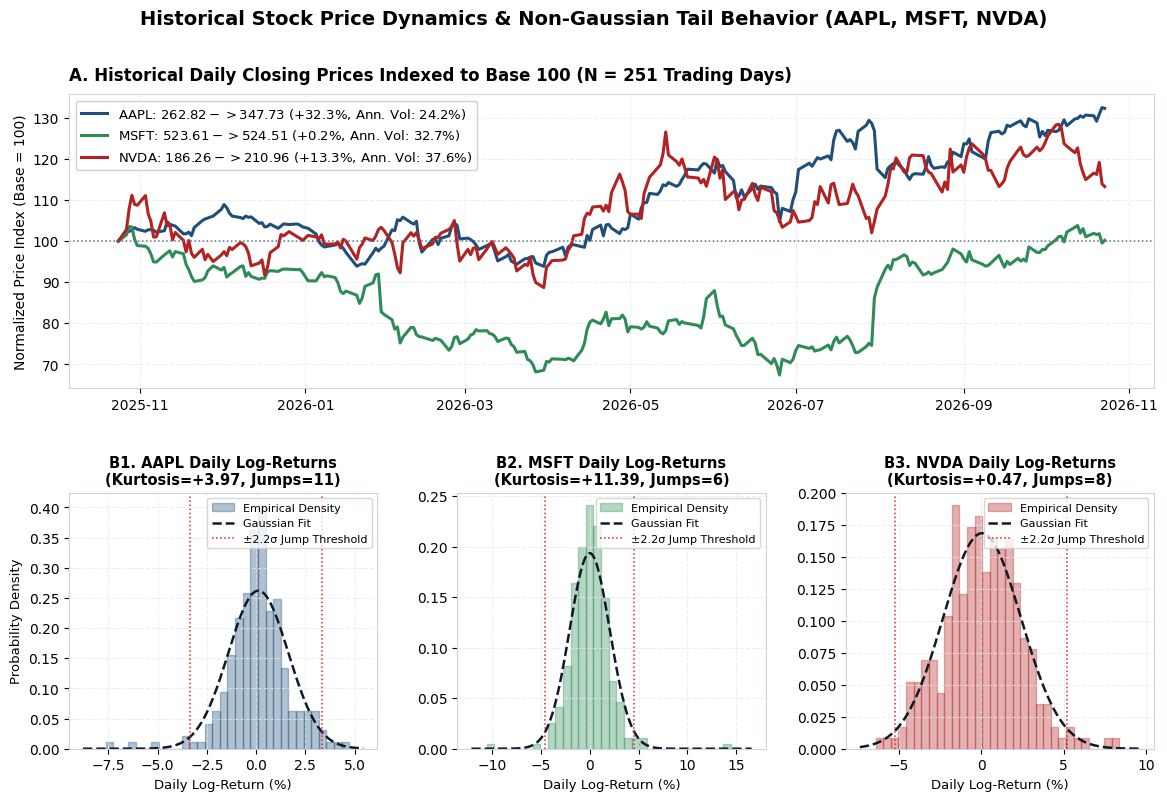

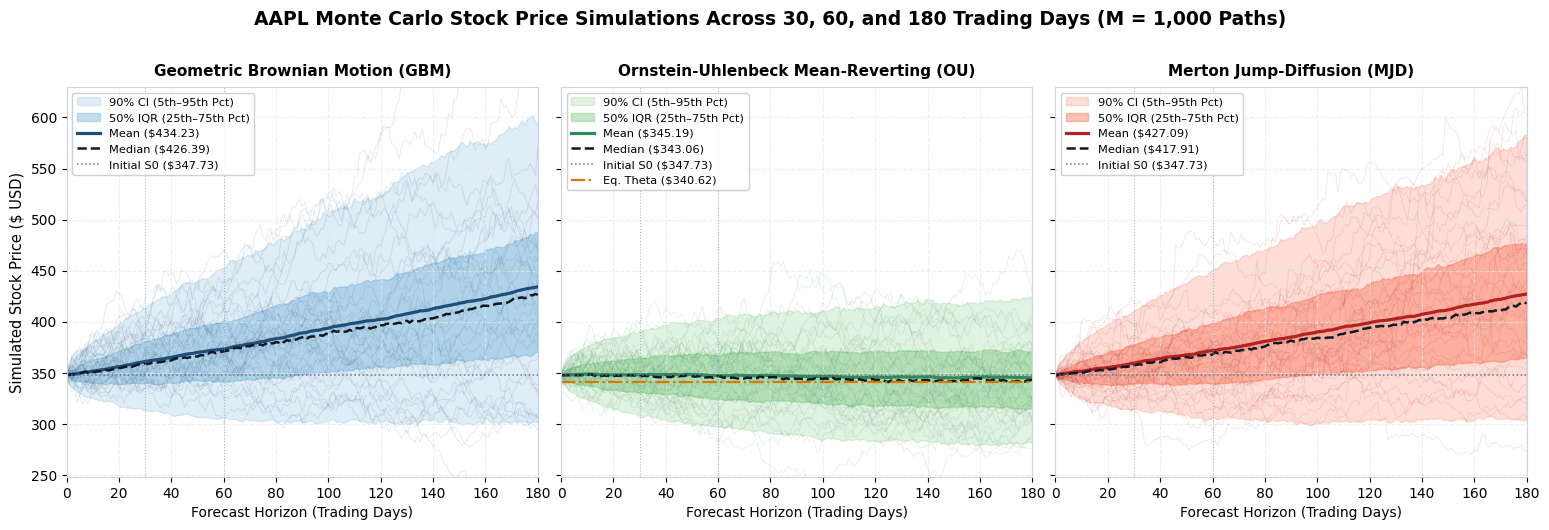

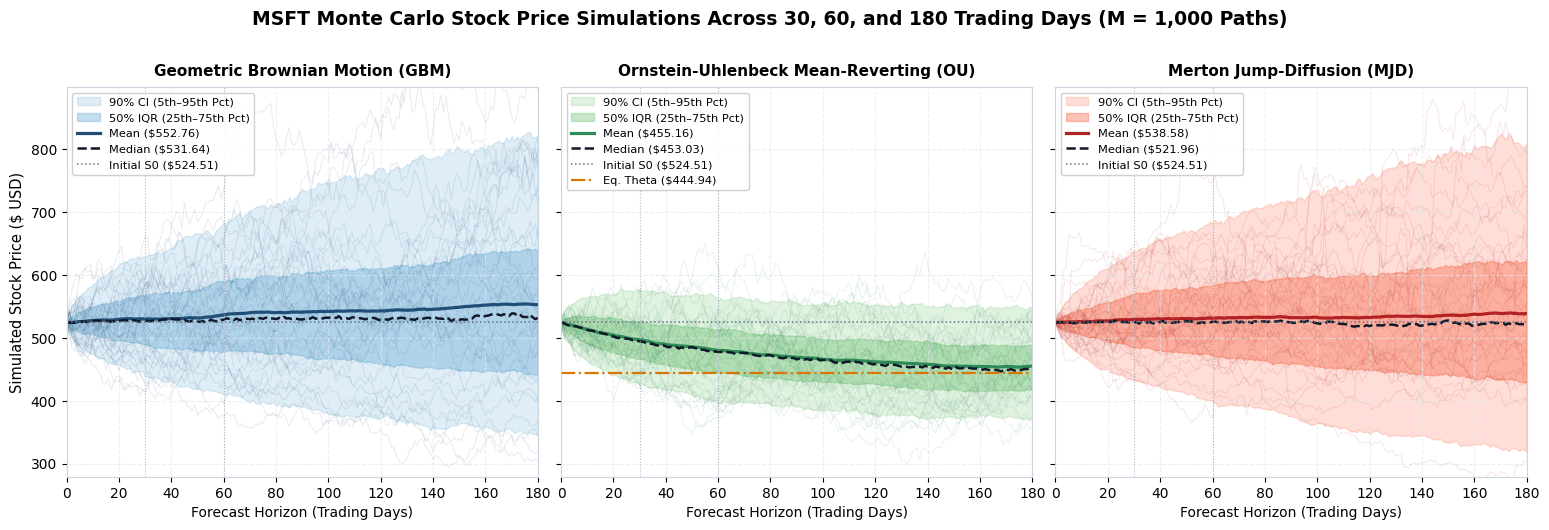

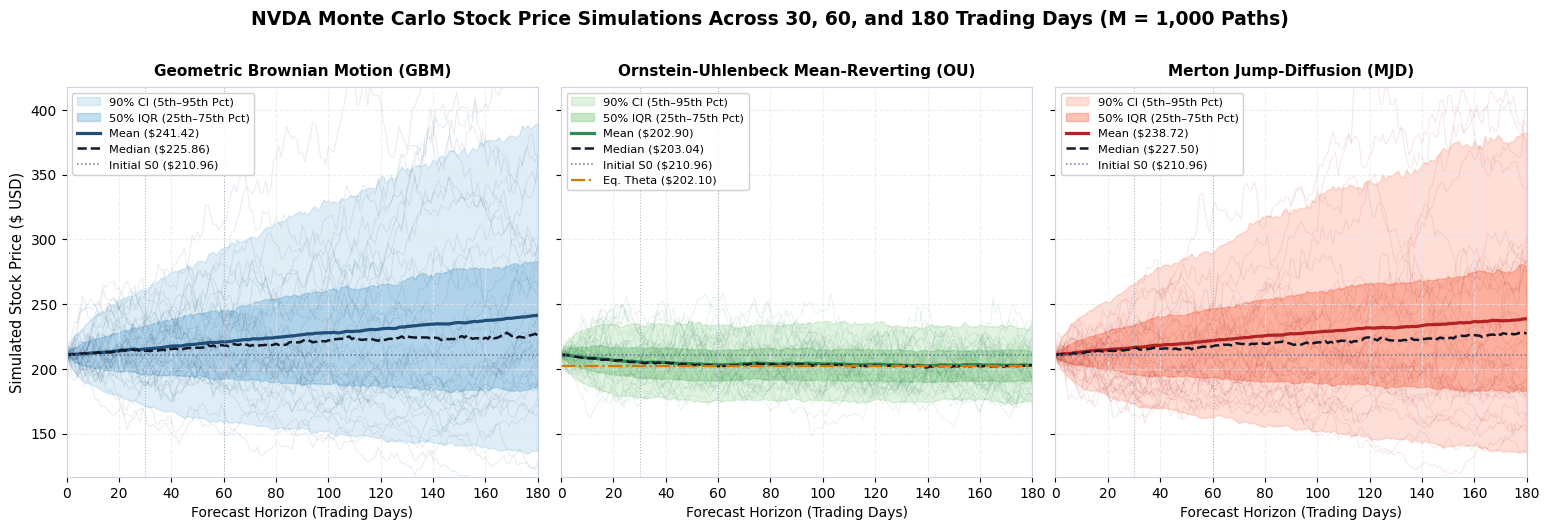

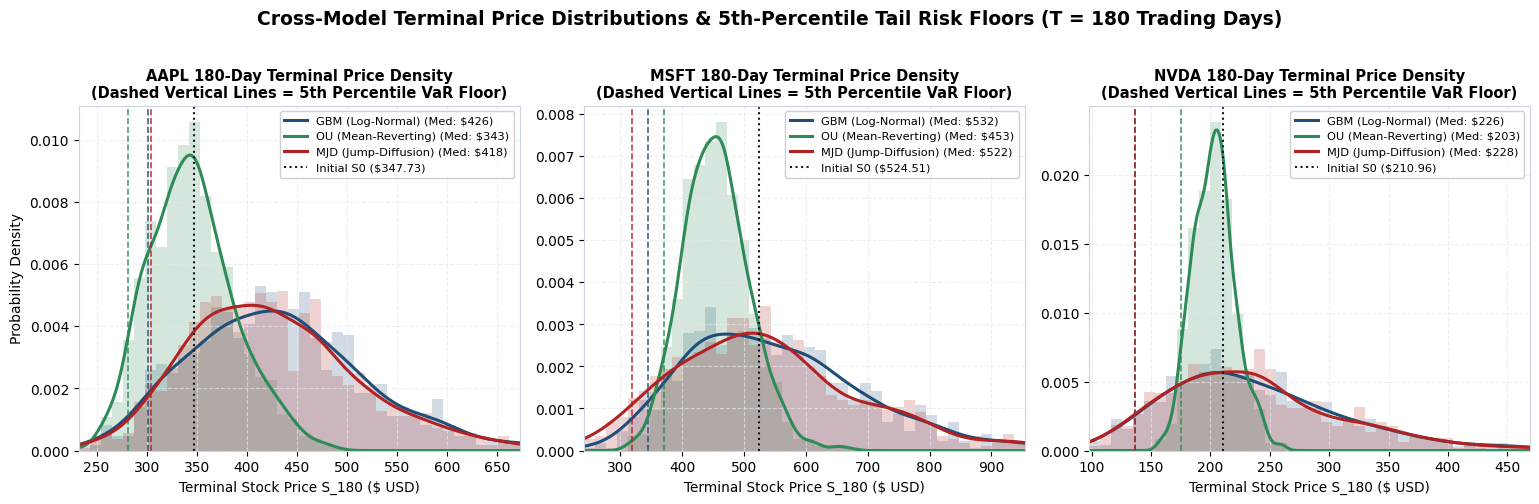

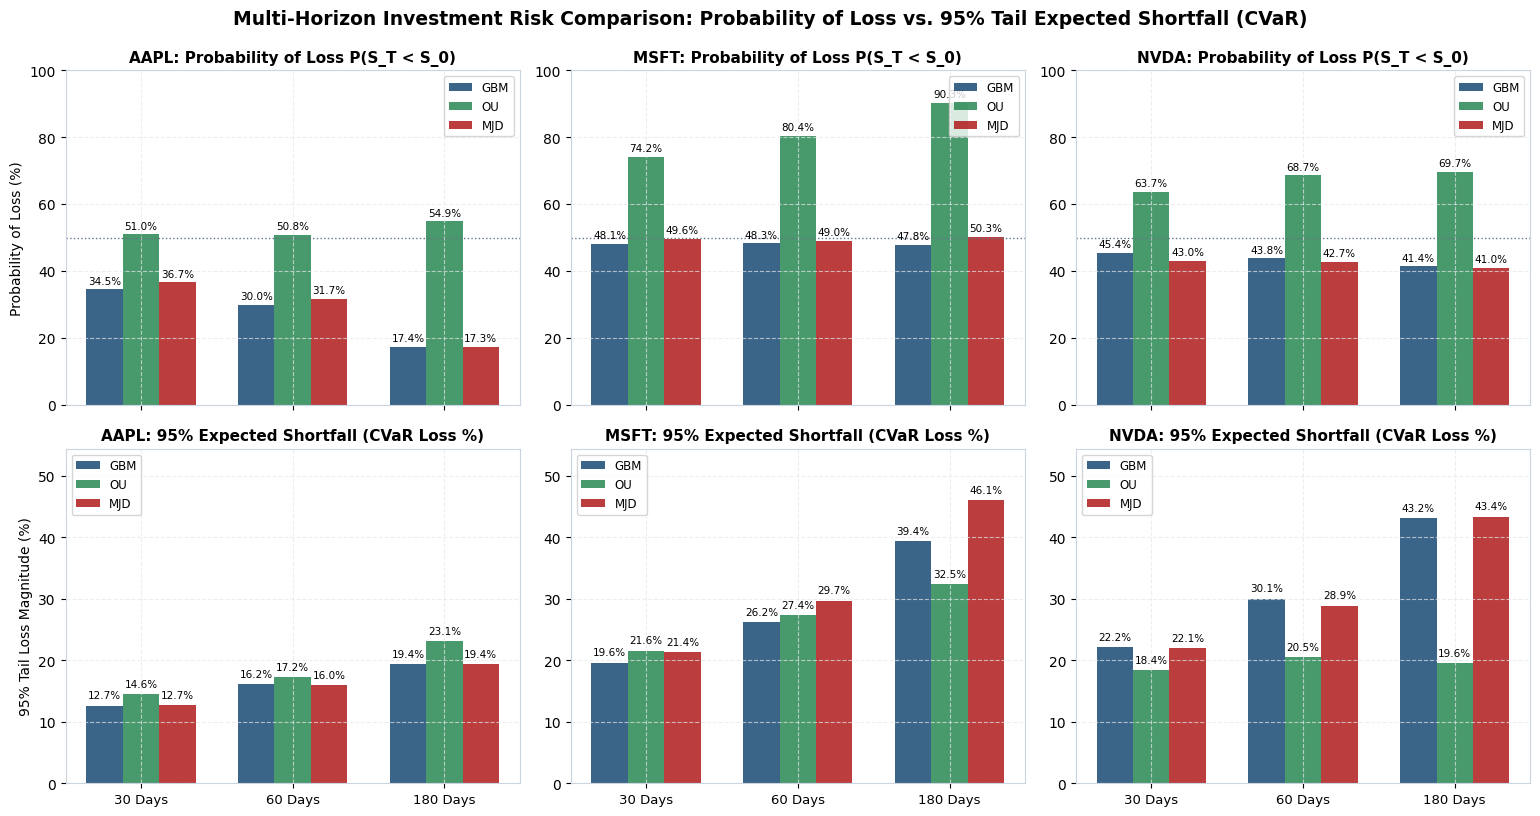


MONTE CARLO SIMULATION SUMMARY (180-DAY HORIZON, M = 1,000 RUNS)
ticker model  initial_price  mean_terminal_price  median_terminal_price  expected_return_pct  prob_loss_pct  var_95_loss_pct  cvar_95_loss_pct
  AAPL   GBM         347.73               434.23                 426.39                24.88           17.4            13.23             19.45
  AAPL    OU         347.73               345.19                 343.06                -0.73           54.9            19.10             23.12
  AAPL   MJD         347.73               427.09                 417.91                22.82           17.3            12.41             19.45
  MSFT   GBM         524.51               552.76                 531.64                 5.39           47.8            34.14             39.38
  MSFT    OU         524.51               455.16                 453.03               -13.22           90.3            29.23             32.47
  MSFT   MJD         524.51               538.58                 521.96     

In [ ]:
# ==============================================================================
# 8. MAIN EXECUTION WORKFLOW
# ==============================================================================

def run_pipeline(
    tickers: List[str] = DEFAULT_TICKERS,
    start_date: str = DEFAULT_START_DATE,
    end_date: str = DEFAULT_END_DATE,
    n_sims: int = DEFAULT_MONTE_CARLO_RUNS,
    horizons: Tuple[int, ...] = DEFAULT_SUBSET_HORIZONS,
    seed: int = GLOBAL_SEED,
    output_dir: str = "./output_artifacts",
    show_inline: bool = True,
) -> Dict:
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)
    csv_path = out_path / "historical_stock_prices.csv"

    raw_df = fetch_yfinance_data(
        tickers=tickers,
        start_date=start_date,
        end_date=end_date,
        csv_cache_path=csv_path,
    )
    prices_df, log_returns_df, summaries = clean_and_preprocess_data(raw_df)
    prices_df.to_csv(csv_path)

    max_horizon = max(horizons)
    rng = np.random.default_rng(seed)

    calibrated_models: Dict[str, Dict[str, Dict]] = {}
    all_horizon_metrics: List[HorizonMetrics] = []
    sim_paths_dict: Dict[str, Dict[str, np.ndarray]] = {}

    for ticker in prices_df.columns:
        prices = prices_df[ticker].values
        rets = log_returns_df[ticker].values
        s0 = float(prices[-1])

        gbm_p = calibrate_gbm(rets)
        ou_p = calibrate_ou(prices)
        mjd_p = calibrate_mjd(rets, threshold_z=2.2)

        calibrated_models[ticker] = {
            "GBM": asdict(gbm_p),
            "OU": asdict(ou_p),
            "MJD": asdict(mjd_p),
        }

        gbm_paths = simulate_gbm_paths(s0, gbm_p, max_horizon, n_sims, rng)
        ou_paths = simulate_ou_paths(s0, ou_p, max_horizon, n_sims, rng)
        mjd_paths = simulate_mjd_paths(s0, mjd_p, max_horizon, n_sims, rng)

        sim_paths_dict[ticker] = {
            "GBM": gbm_paths,
            "OU": ou_paths,
            "MJD": mjd_paths,
        }

        for h in horizons:
            all_horizon_metrics.append(evaluate_simulation_paths(ticker, "GBM", gbm_paths, h))
            all_horizon_metrics.append(evaluate_simulation_paths(ticker, "OU", ou_paths, h))
            all_horizon_metrics.append(evaluate_simulation_paths(ticker, "MJD", mjd_paths, h))

    plot_historical_overview(
        prices_df, log_returns_df, summaries, out_path / "fig1_historical_analysis.png", show_inline
    )
    for idx_t, ticker in enumerate(prices_df.columns):
        plot_stock_monte_carlo_comparison(
            ticker,
            sim_paths_dict[ticker]["GBM"],
            sim_paths_dict[ticker]["OU"],
            sim_paths_dict[ticker]["MJD"],
            OUParams(**calibrated_models[ticker]["OU"]),
            out_path / f"fig{idx_t+2}_{ticker.lower()}_mc_paths.png",
            show_inline,
        )
    plot_terminal_distributions(
        sim_paths_dict, out_path / "fig5_terminal_distributions.png", show_inline
    )
    plot_horizon_risk_comparison(
        all_horizon_metrics, out_path / "fig6_horizon_risk_comparison.png", show_inline
    )

    results_payload = {
        "metadata": {
            "tickers": list(prices_df.columns),
            "n_simulations": n_sims,
            "horizons_days": list(horizons),
            "seed": seed,
            "trading_days_per_year": TRADING_DAYS_PER_YEAR,
            "data_source": "Yahoo Finance (yfinance)",
        },
        "historical_summaries": {k: asdict(v) for k, v in summaries.items()},
        "calibrated_parameters": calibrated_models,
        "simulation_metrics": [asdict(m) for m in all_horizon_metrics],
    }

    json_path = out_path / "simulation_results.json"
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(results_payload, f, indent=2)

    print("\n" + "=" * 92)
    print("MONTE CARLO SIMULATION SUMMARY (180-DAY HORIZON, M = 1,000 RUNS)")
    print("=" * 92)
    summary_df = pd.DataFrame([asdict(m) for m in all_horizon_metrics if m.horizon_days == 180])
    cols = [
        "ticker",
        "model",
        "initial_price",
        "mean_terminal_price",
        "median_terminal_price",
        "expected_return_pct",
        "prob_loss_pct",
        "var_95_loss_pct",
        "cvar_95_loss_pct",
    ]
    print(summary_df[cols].to_string(index=False))
    print("=" * 92)
    print(f"[SUCCESS] All figures and JSON results saved to: {out_path.resolve()}")

    return results_payload


if __name__ == "__main__":
    parser = argparse.ArgumentParser(
        description="Stochastic Processes Stock Price Simulation Engine (Google Colab Ready)"
    )
    parser.add_argument("--tickers", nargs="+", default=DEFAULT_TICKERS, help="List of stock tickers")
    parser.add_argument("--start-date", type=str, default=DEFAULT_START_DATE, help="Start date (YYYY-MM-DD)")
    parser.add_argument("--end-date", type=str, default=DEFAULT_END_DATE, help="End date (YYYY-MM-DD)")
    parser.add_argument("--runs", type=int, default=DEFAULT_MONTE_CARLO_RUNS, help="Monte Carlo runs")
    parser.add_argument("--seed", type=int, default=GLOBAL_SEED, help="Random seed")
    parser.add_argument("--output-dir", type=str, default="./output_artifacts", help="Output directory")

    args, _ = parser.parse_known_args()

    run_pipeline(
        tickers=args.tickers,
        start_date=args.start_date,
        end_date=args.end_date,
        n_sims=args.runs,
        seed=args.seed,
        output_dir=args.output_dir,
        show_inline=True,
    )
